# 1.2 ResNet-50 features: GRAZPEDWRI-DX

`data/processed/` → frozen ResNet-50 features → Logistic Regression / Gradient Boosting → test results

Uses outputs from `0.1_data-pipeline_fahim.ipynb`. ResNet-50 weights are frozen; only the two classifiers are trained, on all training images (casts and follow-ups included). All models use `SEED = 42`.

| Output | Contents |
|---|---|
| `data/interim/graz_resnet50_features.npy` | One 2048-value feature vector per X-ray, same row order as `graz.csv` |
| `models/checkpoints/logistic_regression_seed42.joblib` | Logistic Regression checkpoint |
| `models/checkpoints/gradient_boosting_seed42_iter<N>.joblib` | Gradient Boosting checkpoint every 25 trees |
| `models/resnet50_baseline_predictions.csv` | Test labels, clean/cast flags, probabilities and confidence scores |

In [2]:
import joblib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import models

from snap.config import INTERIM_DATA_DIR, MODELS_DIR, PROCESSED_DATA_DIR

SEED = 42                                      # seed for the folds and both models
N_SPLITS = 5                                   # cross-validation folds
LR_C_VALUES = [0.00001, 0.0001, 0.001, 0.01, 0.1]  # Logistic Regression: regularization strength C
GB_TREE_VALUES = [100, 200, 400]               # Gradient Boosting: number of trees
GB_LEARNING_RATE = 0.05
N_BOOTSTRAP = 1000                             # resamples of test patients for the 95% interval
FEATURE_PATH = INTERIM_DATA_DIR / "graz_resnet50_features.npy"
CHECKPOINT_EVERY = 25                          # save a Gradient Boosting checkpoint every N trees
RETRAIN = False                                # True = ignore saved checkpoints and train from scratch

CHECKPOINT_DIR = MODELS_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Load data

`graz.csv` has the train/validation/test split by patient, and its rows match the image array.

In [3]:
df = pd.read_csv(PROCESSED_DATA_DIR / "graz.csv")
y = df["label"].to_numpy()

train_mask = (df["split"] == "train").to_numpy()
val_mask = (df["split"] == "val").to_numpy()
test_mask = (df["split"] == "test").to_numpy()

for name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
    print(f"{name}: {mask.sum()} images, {y[mask].mean():.0%} fracture")

train: 14182 images, 67% fracture
val: 3202 images, 69% fracture
test: 2943 images, 65% fracture


## 2. ResNet-50 features

ImageNet ResNet-50 (`IMAGENET1K_V2`) with the final classification layer removed, so each X-ray becomes 2048 features. The weights are frozen.
Each image keeps its full 512×256 size; the grayscale image is copied into 3 channels and normalized with ImageNet values.
The features are saved once and reloaded after that.

In [ ]:
class WristDataset(Dataset):
    def __init__(self, images):
        self.images = images
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = torch.from_numpy(np.array(self.images[idx], copy=True)).float() / 255.0  # (512, 256), values 0 to 1
        image = image.unsqueeze(0).repeat(3, 1, 1)                                        # (3, 512, 256)
        return (image - self.mean) / self.std


if FEATURE_PATH.exists():
    print("Loading cached features...")
else:
    images = np.load(PROCESSED_DATA_DIR / "graz_256x512_u8.npy", mmap_mode="r")
    loader = DataLoader(WristDataset(images), batch_size=32, shuffle=False, num_workers=0)  # workers hang in Windows notebooks

    resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    resnet.fc = nn.Identity()
    for param in resnet.parameters():
        param.requires_grad = False
    resnet = resnet.to(device)
    resnet.eval()

    all_features = []
    with torch.no_grad():
        for batch in loader:
            features = resnet(batch.to(device))  # (batch, 2048)
            all_features.append(features.cpu().numpy())
    np.save(FEATURE_PATH, np.concatenate(all_features).astype(np.float32))
    print("Saved features:", FEATURE_PATH.name)

features_array = np.load(FEATURE_PATH)
assert features_array.shape == (len(df), 2048), "Features and labels must align"
print("Feature shape:", features_array.shape)

X_train, y_train = features_array[train_mask], y[train_mask]
X_val, y_val = features_array[val_mask], y[val_mask]
X_test = features_array[test_mask]
groups_train = df.loc[train_mask, "patient_id"].to_numpy()

Loading cached features...
Feature shape: (20327, 2048)


## 3. Models

- **Logistic Regression:** standardized features. It has no randomness.
- **Gradient Boosting:** `HistGradientBoostingClassifier`. Each split looks at a random half of the features (`max_features=0.5`), which is where the seed matters. `early_stopping=False` so the number of trees is exactly the value asked for.

In [5]:
def make_lr(C, seed):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, max_iter=2000, random_state=seed),
    )


def make_gb(n_trees, seed):
    return HistGradientBoostingClassifier(
        max_iter=n_trees,
        learning_rate=GB_LEARNING_RATE,
        max_features=0.5,
        early_stopping=False,
        random_state=seed,
    )

## 4. Cross-validation

5-fold `StratifiedGroupKFold` on the training split, grouped by `patient_id` so no patient is in both parts of a fold. Every setting is scored on the same folds, and the one with the highest mean AUC is kept.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(sgkf.split(X_train, y_train, groups=groups_train))


def run_cv(make_fn, values, value_name):
    rows = []
    for value in values:
        fold_aucs = []
        for train_idx, val_idx in folds:
            clf = make_fn(value, SEED)
            clf.fit(X_train[train_idx], y_train[train_idx])
            probs = clf.predict_proba(X_train[val_idx])[:, 1]
            fold_aucs.append(roc_auc_score(y_train[val_idx], probs))
        rows.append({value_name: value, "CV Mean AUC": np.mean(fold_aucs), "CV Std AUC": np.std(fold_aucs)})
        print(f"  {value_name}={value}: AUC {np.mean(fold_aucs):.3f} +/- {np.std(fold_aucs):.3f}")
    cv_df = pd.DataFrame(rows)
    display(cv_df.round({"CV Mean AUC": 3, "CV Std AUC": 3}))
    return cv_df.loc[cv_df["CV Mean AUC"].idxmax(), value_name]

## 5. Logistic Regression

Pick `C` by cross-validation, refit on the whole training split and save to `models/checkpoints/logistic_regression_seed42.joblib`.
If the checkpoint exists and `RETRAIN = False`, it is reloaded and cross-validation is skipped.

In [7]:
lr_ckpt = CHECKPOINT_DIR / f"logistic_regression_seed{SEED}.joblib"

if lr_ckpt.exists() and not RETRAIN:
    print(f"Loading Logistic Regression checkpoint: {lr_ckpt.name}")
    lr_model = joblib.load(lr_ckpt)
else:
    best_C = float(run_cv(make_lr, LR_C_VALUES, "C"))
    print(f"Training Logistic Regression with C={best_C}...")
    lr_model = make_lr(best_C, SEED)
    lr_model.fit(X_train, y_train)
    joblib.dump(lr_model, lr_ckpt)
    print(f"Saved checkpoint: {lr_ckpt.name}")

best_C = lr_model.named_steps["logisticregression"].C
val_auc = roc_auc_score(y_val, lr_model.predict_proba(X_val)[:, 1])
print(f"C={best_C}  validation ROC-AUC: {val_auc:.4f}")

  C=1e-05: AUC 0.839 +/- 0.006


  C=0.0001: AUC 0.884 +/- 0.007


  C=0.001: AUC 0.907 +/- 0.005


  C=0.01: AUC 0.902 +/- 0.005


  C=0.1: AUC 0.885 +/- 0.006


,C,CV Mean AUC,CV Std AUC
0,0.00001,0.839,0.006
1,0.00010,0.884,0.007
2,0.00100,0.907,0.005
3,0.01000,0.902,0.005
4,0.10000,0.885,0.006


Training Logistic Regression with C=0.001...


Saved checkpoint: logistic_regression_seed42.joblib
C=0.001  validation ROC-AUC: 0.9108


## 6. Gradient Boosting

Pick the number of trees by cross-validation, then train on the whole training split with `warm_start=True`, adding `CHECKPOINT_EVERY` trees at a time and saving a checkpoint after each step: `models/checkpoints/gradient_boosting_seed42_iter<N>.joblib`.
If checkpoints exist and `RETRAIN = False`, the one with the most trees is reloaded and cross-validation is skipped.

In [8]:
gb_iters = []
for path in CHECKPOINT_DIR.glob(f"gradient_boosting_seed{SEED}_iter*.joblib"):
    gb_iters.append(int(path.stem.split("iter")[-1]))

if gb_iters and not RETRAIN:
    final_ckpt = CHECKPOINT_DIR / f"gradient_boosting_seed{SEED}_iter{max(gb_iters)}.joblib"
    print(f"Loading Gradient Boosting checkpoint: {final_ckpt.name}")
    gb_model = joblib.load(final_ckpt)
else:
    best_trees = int(run_cv(make_gb, GB_TREE_VALUES, "trees"))
    print(f"Training Gradient Boosting with {best_trees} trees (warm start)...")
    gb_model = make_gb(CHECKPOINT_EVERY, SEED)
    gb_model.set_params(warm_start=True)

    current_iter = 0
    while current_iter < best_trees:
        current_iter = min(current_iter + CHECKPOINT_EVERY, best_trees)
        gb_model.max_iter = current_iter
        gb_model.fit(X_train, y_train)
        ckpt = CHECKPOINT_DIR / f"gradient_boosting_seed{SEED}_iter{current_iter}.joblib"
        joblib.dump(gb_model, ckpt)
    print(f"Saved checkpoints up to: {ckpt.name}")

best_trees = gb_model.max_iter
val_auc = roc_auc_score(y_val, gb_model.predict_proba(X_val)[:, 1])
print(f"trees={best_trees}  validation ROC-AUC: {val_auc:.4f}")

final_models = {"lr": lr_model, "gb": gb_model}

  trees=100: AUC 0.892 +/- 0.003


  trees=200: AUC 0.901 +/- 0.002


  trees=400: AUC 0.906 +/- 0.002


,trees,CV Mean AUC,CV Std AUC
0,100,0.892,0.003
1,200,0.901,0.002
2,400,0.906,0.002


Training Gradient Boosting with 400 trees (warm start)...


Saved checkpoints up to: gradient_boosting_seed42_iter400.joblib
trees=400  validation ROC-AUC: 0.9090


### Save predictions with confidence scores

Test labels, clean/cast flags, fracture probability and a **confidence score** per model. The confidence score is `2 * |p - 0.5|`: 0 at p = 0.5, 1 at p = 0 or 1. It says how far the probability is from 0.5, whether the prediction is right or wrong.

Output: `models/resnet50_baseline_predictions.csv`.

In [9]:
predictions_df = df.loc[test_mask, ["filestem", "patient_id", "label", "cast", "clean", "split"]].copy().reset_index(drop=True)

for name, model in [("logistic_regression", lr_model), ("gradient_boosting", gb_model)]:
    probs = model.predict_proba(X_test)[:, 1]
    predictions_df[f"{name}_seed{SEED}_prob"] = probs
    predictions_df[f"{name}_seed{SEED}_confidence"] = 2.0 * np.abs(probs - 0.5)

predictions_path = MODELS_DIR / "resnet50_baseline_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)
print("Predictions saved:", predictions_path.name, predictions_df.shape)

Predictions saved: resnet50_baseline_predictions.csv (2943, 10)


## 7. Learning curves

Log loss (left) and AUC (right) on the training and validation splits as training goes on.
Logistic Regression is refit with 1 to 40 solver (L-BFGS) steps; Gradient Boosting is scored after each tree of the final model.
Validation loss rising while training loss falls means overfitting.

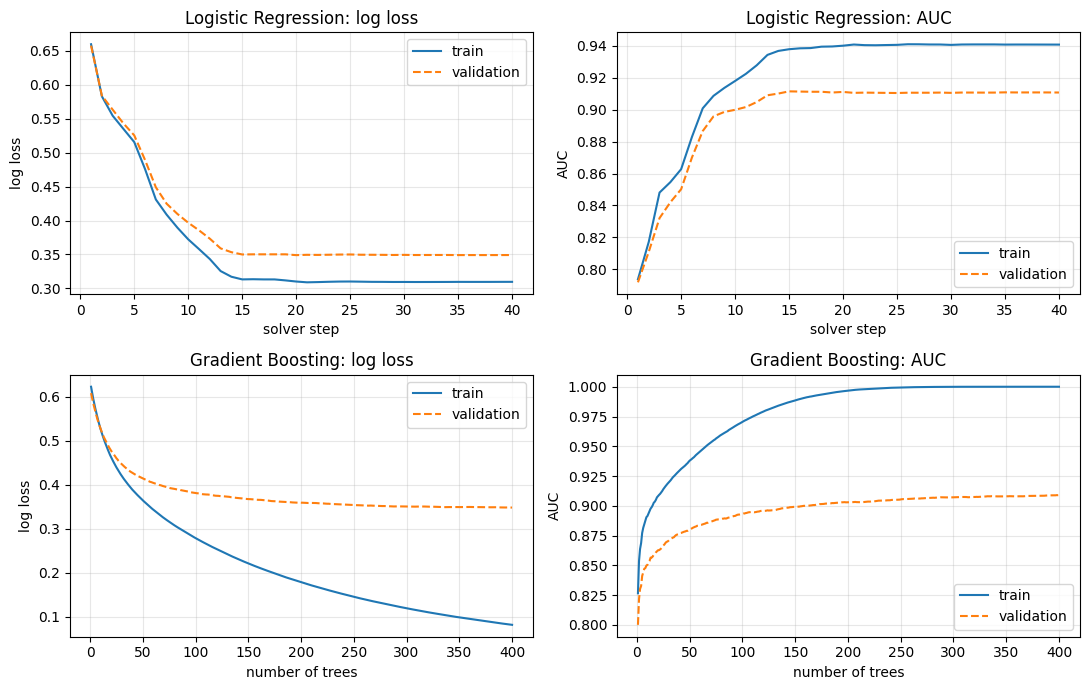

LR after 40 steps: val loss 0.349, val AUC 0.911
GB: val loss 0.348 (lowest 0.348 at tree 400), val AUC 0.909


In [10]:
def loss_and_auc(y_true, probs):
    return log_loss(y_true, probs), roc_auc_score(y_true, probs)


# Logistic Regression: one refit per number of solver steps
lr_steps = np.arange(1, 41)
lr_train, lr_val = [], []
for n_steps in lr_steps:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=n_steps, random_state=SEED))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)  # stopping early on purpose
        clf.fit(X_train, y_train)
    lr_train.append(loss_and_auc(y_train, clf.predict_proba(X_train)[:, 1]))
    lr_val.append(loss_and_auc(y_val, clf.predict_proba(X_val)[:, 1]))

# Gradient Boosting: scores after each tree
gb_train = [loss_and_auc(y_train, p[:, 1]) for p in final_models["gb"].staged_predict_proba(X_train)]
gb_val = [loss_and_auc(y_val, p[:, 1]) for p in final_models["gb"].staged_predict_proba(X_val)]
gb_trees = np.arange(1, len(gb_val) + 1)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
curves = [("Logistic Regression", "solver step", lr_steps, np.array(lr_train), np.array(lr_val)),
          ("Gradient Boosting", "number of trees", gb_trees, np.array(gb_train), np.array(gb_val))]
for row, (name, xlabel, x, train_curve, val_curve) in enumerate(curves):
    for col, metric in enumerate(["log loss", "AUC"]):
        ax = axes[row, col]
        ax.plot(x, train_curve[:, col], label="train")
        ax.plot(x, val_curve[:, col], linestyle="--", label="validation")
        ax.set(xlabel=xlabel, ylabel=metric, title=f"{name}: {metric}")
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.show()

lowest = int(np.argmin(np.array(gb_val)[:, 0]))
print(f"LR after 40 steps: val loss {lr_val[-1][0]:.3f}, val AUC {lr_val[-1][1]:.3f}")
print(f"GB: val loss {gb_val[-1][0]:.3f} (lowest {gb_val[lowest][0]:.3f} at tree {gb_trees[lowest]}), val AUC {gb_val[-1][1]:.3f}")

## 8. Test results

- **AUC** is the main metric.
- **Sensitivity and specificity** use one threshold per model, picked on the validation split (Youden's J: the point on the ROC curve farthest above the diagonal).
- **Test sets:** full, clean (first visit, no cast), no cast, cast.
- **95% interval:** patient-level bootstrap, resampling test patients 1,000 times.

In [11]:
test_df = df[test_mask].copy()
thresholds = {}
for key, model in final_models.items():
    fpr, tpr, thr = roc_curve(y_val, model.predict_proba(X_val)[:, 1])
    thresholds[key] = thr[np.argmax(tpr - fpr)]
    test_df[f"prob_{key}"] = model.predict_proba(X_test)[:, 1]
print("Thresholds:", {key: round(float(t), 3) for key, t in thresholds.items()})

subsets = {
    "Full test": test_df,
    "Clean test": test_df[test_df["clean"] == 1],
    "No cast": test_df[test_df["cast"] == 0],
    "Cast": test_df[test_df["cast"] == 1],
}
model_names = {"lr": "Logistic Regression", "gb": "Gradient Boosting"}


def scores(part, key):
    labels = part["label"].to_numpy()
    probs = part[f"prob_{key}"].to_numpy()
    predicted = probs >= thresholds[key]
    auc = roc_auc_score(labels, probs)
    sensitivity = predicted[labels == 1].mean()     # share of fractures found
    specificity = (~predicted[labels == 0]).mean()  # share of normal wrists called normal
    return [auc, sensitivity, specificity]


def bootstrap_interval(part, key):
    rng = np.random.default_rng(0)
    patient_rows = part.groupby("patient_id").indices  # patient id -> row positions
    patients = list(patient_rows)
    results = []
    for _ in range(N_BOOTSTRAP):
        sampled = rng.choice(patients, size=len(patients), replace=True)
        rows = np.concatenate([patient_rows[p] for p in sampled])
        resample = part.iloc[rows]
        if resample["label"].nunique() < 2:
            continue  # AUC needs both classes
        results.append(scores(resample, key))
    return np.percentile(results, [2.5, 97.5], axis=0)


results = []
for key, name in model_names.items():
    for subset_name, part in subsets.items():
        value = scores(part, key)
        low, high = bootstrap_interval(part, key)
        row = {"Model": name, "Test set": subset_name, "Images": len(part), "Normal": int((part["label"] == 0).sum())}
        for i, metric in enumerate(["AUC", "Sensitivity", "Specificity"]):
            row[metric] = f"{value[i]:.3f} [{low[i]:.3f}, {high[i]:.3f}]"
        row["auc"] = value[0]  # plain number, used for the gap below
        results.append(row)
results_df = pd.DataFrame(results)
display(results_df.drop(columns="auc"))

for key, name in model_names.items():
    rows = results_df[results_df["Model"] == name].set_index("Test set")
    print(f"{name}: shortcut gap (full - clean AUC) {rows.loc['Full test', 'auc'] - rows.loc['Clean test', 'auc']:.3f}")

Thresholds: {'lr': 0.604, 'gb': 0.704}


,Model,Test set,Images,Normal,AUC,Sensitivity,Specificity
0,Logistic Regression,Full test,2943,1044,"0.918 [0.904, 0.931]","0.838 [0.815, 0.860]","0.857 [0.834, 0.880]"
1,Logistic Regression,Clean test,1637,987,"0.861 [0.840, 0.882]","0.631 [0.590, 0.671]","0.887 [0.866, 0.907]"
2,Logistic Regression,No cast,2124,1013,"0.890 [0.873, 0.906]","0.727 [0.697, 0.762]","0.884 [0.864, 0.904]"
3,Logistic Regression,Cast,819,31,"0.645 [0.575, 0.721]","0.995 [0.989, 0.999]","0.000 [0.000, 0.000]"
4,Gradient Boosting,Full test,2943,1044,"0.918 [0.904, 0.932]","0.810 [0.786, 0.833]","0.889 [0.867, 0.910]"
5,Gradient Boosting,Clean test,1637,987,"0.861 [0.841, 0.882]","0.598 [0.556, 0.640]","0.919 [0.901, 0.936]"
6,Gradient Boosting,No cast,2124,1013,"0.889 [0.872, 0.906]","0.677 [0.642, 0.710]","0.916 [0.899, 0.933]"
7,Gradient Boosting,Cast,819,31,"0.640 [0.558, 0.736]","0.997 [0.994, 1.000]","0.000 [0.000, 0.000]"


Logistic Regression: shortcut gap (full - clean AUC) 0.057
Gradient Boosting: shortcut gap (full - clean AUC) 0.057


### ROC curves

Solid: full test, dashed: clean test.

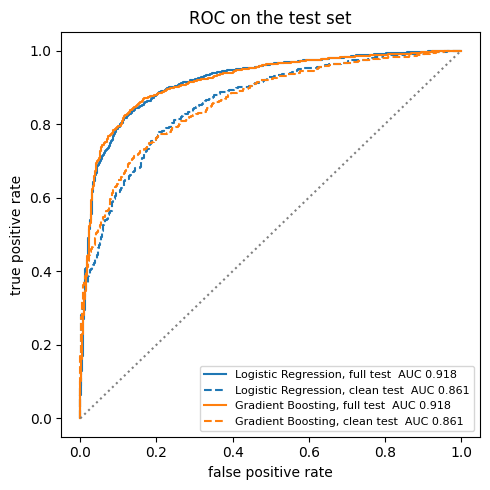

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
for key, name in model_names.items():
    for subset_name, style in [("Full test", "-"), ("Clean test", "--")]:
        part = subsets[subset_name]
        fpr, tpr, _ = roc_curve(part["label"], part[f"prob_{key}"])
        auc = roc_auc_score(part["label"], part[f"prob_{key}"])
        ax.plot(fpr, tpr, linestyle=style, color="C0" if key == "lr" else "C1",
                label=f"{name}, {subset_name.lower()}  AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":")
ax.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC on the test set")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Findings

Seed 42, patient-level bootstrap 95% interval in brackets.

- **Cross-validation:** `C=0.001` for Logistic Regression (CV AUC 0.907) and 400 trees for Gradient Boosting (0.906).
- **Test AUC:** Both models yield 0.918 [0.904, 0.931] on the full test set and 0.861 on the clean subset. The 0.057 difference indicates that the models do better when the casts are present and suggests a possible shortcut.
- **Casts:** All 31 normal wrists in a cast are classified as fractures (specificity 0.00; probabilities 0.74> for LR, 0.92> for GB), and sensitivity under a cast is 0.995-0.997. The models treat the cast as a fracture sign. Cast AUC is low (LR 0.65, GB 0.64), so within cast images the models can't reliably distinguish fractured wrists from normal wrists. With only 31 normal cast images, these numbers are rough.
- **Learning curves:** Logistic Regression converges well within 40 solver steps (validation loss 0.349). Gradient Boosting fits the training set almost perfectly; validation loss is still falling slowly at tree 400 (0.348), so more trees wouldn't provide much more help.